# Step 1: Install Dependencies
This step installs the `pgmpy` library required for Bayesian Network construction and inference.

In [1]:
!pip install -q pgmpy

# Step 2: Import Libraries
Here we import the necessary components from `pgmpy` for defining our model structures, conditional probability distributions, and performing inference.

In [2]:
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


# Step 3: Define Network Structure
We define our Bayesian Network's graphical structure by establishing the directed edge relationships (Parent -> Child) between key variables.

In [3]:
# Define the Bayesian Network structure using directed edges (Parent -> Child)
model = BayesianNetwork([
    ('Attendance', 'StudyTime'),
    ('SocialLife', 'StudyTime'),
    ('StudyTime', 'Performance'),
    ('Health', 'Performance')
])

print("Nodes in network:", list(model.nodes()))
print("Edges in network:", list(model.edges()))

Nodes in network: ['Attendance', 'StudyTime', 'SocialLife', 'Performance', 'Health']
Edges in network: [('Attendance', 'StudyTime'), ('StudyTime', 'Performance'), ('SocialLife', 'StudyTime'), ('Health', 'Performance')]


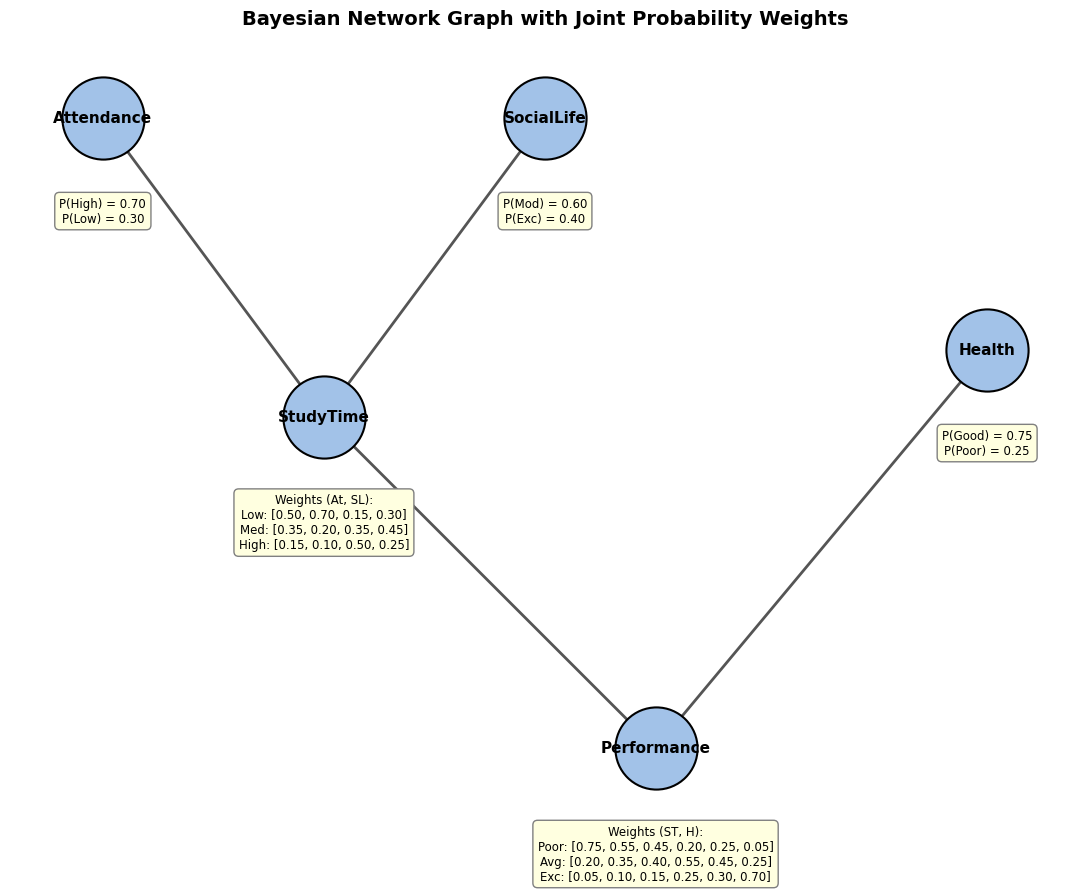

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph object
G = nx.DiGraph()
G.add_edges_from(model.edges())

# Optimized layout coordinates for readability
pos = {
    'Attendance': (0, 2),
    'SocialLife': (2.5, 2),
    'Health': (5, 1.3),
    'StudyTime': (1.25, 1.1),
    'Performance': (3.125, 0.1)
}

plt.figure(figsize=(11, 9))

# Draw nodes with stylized aesthetics
nx.draw_networkx_nodes(G, pos, node_size=3500, node_color='#a2c2e8', edgecolors='black', linewidths=1.5)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=25, edge_color='#555555', width=2)
nx.draw_networkx_labels(G, pos, font_size=11, font_weight='bold')

# Define explicit probability weights to display on the graph
annotations = {
    'Attendance': "P(High) = 0.70\nP(Low) = 0.30",
    'SocialLife': "P(Mod) = 0.60\nP(Exc) = 0.40",
    'Health': "P(Good) = 0.75\nP(Poor) = 0.25",
    'StudyTime': "Weights (At, SL):\nLow: [0.50, 0.70, 0.15, 0.30]\nMed: [0.35, 0.20, 0.35, 0.45]\nHigh: [0.15, 0.10, 0.50, 0.25]",
    'Performance': "Weights (ST, H):\nPoor: [0.75, 0.55, 0.45, 0.20, 0.25, 0.05]\nAvg: [0.20, 0.35, 0.40, 0.55, 0.45, 0.25]\nExc: [0.05, 0.10, 0.15, 0.25, 0.30, 0.70]"
}

# Render annotations in clean layout boxes below each node
for node, text in annotations.items():
    x, y = pos[node]
    # Adjusted vertical offsets to prevent overlapping with edges
    offset_y = -0.32 if node in ['StudyTime', 'Performance'] else -0.28
    plt.text(x, y + offset_y, text, fontsize=8.5, ha='center', va='center',
             bbox=dict(boxstyle="round,pad=0.4", fc="#ffffe0", ec="gray", lw=1))

plt.title("Bayesian Network Graph with Joint Probability Weights", fontsize=14, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

# Step 4: Define Conditional Probability Distributions (CPDs)
In this step, we specify the conditional probability tables (CPTs) for each node based on their parent dependencies and state domains.

In [4]:
# 1. CPD for Attendance (0: Low, 1: High) - Matches Lab Guideline template
cpd_attendance = TabularCPD(
    variable='Attendance',
    variable_card=2,
    values=[[0.3],   # P(Attendance = Low)
            [0.7]],  # P(Attendance = High)
    state_names={'Attendance': ['Low', 'High']}
)

# 2. CPD for SocialLife (0: Moderate, 1: Excessive)
cpd_social_life = TabularCPD(
    variable='SocialLife',
    variable_card=2,
    values=[[0.6],   # P(SocialLife = Moderate)
            [0.4]],  # P(SocialLife = Excessive)
    state_names={'SocialLife': ['Moderate', 'Excessive']}
)

# 3. CPD for Health (0: Poor, 1: Good)
cpd_health = TabularCPD(
    variable='Health',
    variable_card=2,
    values=[[0.25],  # P(Health = Poor)
            [0.75]], # P(Health = Good)
    state_names={'Health': ['Poor', 'Good']}
)

# 4. CPD for StudyTime (0: Low, 1: Medium, 2: High)
# Parents: Attendance (Low, High), SocialLife (Moderate, Excessive)
# Columns order: (Low, Moderate), (Low, Excessive), (High, Moderate), (High, Excessive)
cpd_study_time = TabularCPD(
    variable='StudyTime',
    variable_card=3,
    values=[
        [0.50, 0.70, 0.15, 0.30],  # StudyTime = Low
        [0.35, 0.20, 0.35, 0.45],  # StudyTime = Medium
        [0.15, 0.10, 0.50, 0.25]   # StudyTime = High
    ],
    evidence=['Attendance', 'SocialLife'],
    evidence_card=[2, 2],
    state_names={
        'StudyTime': ['Low', 'Medium', 'High'],
        'Attendance': ['Low', 'High'],
        'SocialLife': ['Moderate', 'Excessive']
    }
)

# 5. CPD for Performance (0: Poor, 1: Average, 2: Excellent)
# Parents: StudyTime (Low, Medium, High), Health (Poor, Good)
# Columns order: (Low, Poor), (Low, Good), (Medium, Poor), (Medium, Good), (High, Poor), (High, Good)
cpd_performance = TabularCPD(
    variable='Performance',
    variable_card=3,
    values=[
        [0.75, 0.55, 0.45, 0.20, 0.25, 0.05],  # Performance = Poor
        [0.20, 0.35, 0.40, 0.55, 0.45, 0.25],  # Performance = Average
        [0.05, 0.10, 0.15, 0.25, 0.30, 0.70]   # Performance = Excellent
    ],
    evidence=['StudyTime', 'Health'],
    evidence_card=[3, 2],
    state_names={
        'Performance': ['Poor', 'Average', 'Excellent'],
        'StudyTime': ['Low', 'Medium', 'High'],
        'Health': ['Poor', 'Good']
    }
)

# Step 5: Construct and Validate the Model
We associate the defined CPDs with our Bayesian Network structure and run internal validation checks to guarantee mathematical and structural consistency.

In [5]:
# Add all CPDs to the Bayesian Network
model.add_cpds(
    cpd_attendance,
    cpd_social_life,
    cpd_health,
    cpd_study_time,
    cpd_performance
)

# Verify the correctness and consistency of the model
assert model.check_model()
print("Model verification successful: Structure and CPDs are valid and consistent!")

Model verification successful: Structure and CPDs are valid and consistent!


# Step 6: Perform Inference Queries
Using the Variable Elimination inference engine, we run specific queries to compute marginal probabilities of target variables given our evidence conditions.

In [8]:
# Initialize the Variable Elimination inference engine
inference = VariableElimination(model)

# Query 1 (Lab Task Requirement): P(Performance | StudyTime > 3 hours ['High'], Health = 'Good')
print("--- Query 1: P(Performance | StudyTime > 3 hours ('High'), Health='Good') ---")
result_study_health = inference.query(
    variables=['Performance'],
    evidence={'StudyTime': 'High', 'Health': 'Good'}
)
print(result_study_health)

# Query 2: Forward Inference - P(Performance | Attendance='High', SocialLife='Moderate', Health='Good')
print("\n--- Query 2: P(Performance | Attendance='High', SocialLife='Moderate', Health='Good') ---")
result_indirect = inference.query(
    variables=['Performance'],
    evidence={'Attendance': 'High', 'SocialLife': 'Moderate', 'Health': 'Good'}
)
print(result_indirect)

# Query 3: Backward Diagnostic Inference - P(StudyTime | Performance='Poor')
print("\n--- Query 3: P(StudyTime | Performance='Poor') ---")
result_backwards = inference.query(
    variables=['StudyTime'],
    evidence={'Performance': 'Poor'}
)
print(result_backwards)

# Query 4: Single-Factor Impact - P(Performance | SocialLife='Excessive')
print("\n--- Query 4: P(Performance | SocialLife='Excessive') ---")
result_social_impact = inference.query(
    variables=['Performance'],
    evidence={'SocialLife': 'Excessive'}
)
print(result_social_impact)

--- Query 1: P(Performance | StudyTime > 3 hours ('High'), Health='Good') ---
+------------------------+--------------------+
| Performance            |   phi(Performance) |
+========================+====================+
| Performance(Poor)      |             0.0500 |
+------------------------+--------------------+
| Performance(Average)   |             0.2500 |
+------------------------+--------------------+
| Performance(Excellent) |             0.7000 |
+------------------------+--------------------+

--- Query 2: P(Performance | Attendance='High', SocialLife='Moderate', Health='Good') ---
+------------------------+--------------------+
| Performance            |   phi(Performance) |
+========================+====================+
| Performance(Poor)      |             0.1775 |
+------------------------+--------------------+
| Performance(Average)   |             0.3700 |
+------------------------+--------------------+
| Performance(Excellent) |             0.4525 |
+--------------